In [11]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import pandas as pd
import polars as pl
import time
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import config
from src.io_utils import inspect_raw_file, make_sample_200k, read_csv_auto, benchmark_formats

# Проверяем файлы в data/raw без полного открытия
inspect_raw_file("../" + config.RAW_GEONAMES)
inspect_raw_file("../" + config.RAW_CITIES)
inspect_raw_file("../" + config.RAW_POPULATION)

# Делаем потоковый срез на 200 000 строк из большого файла geonames.csv
make_sample_200k("../" + config.RAW_GEONAMES, "../" + config.SAMPLE_CSV, num_rows=200000)

Файл: ../data/raw/geonames.csv
Размер: 1404.47 МБ
Строка 0: geonameid,name,asciiname,alternatenames,latitude,longitude,feature class,feature code,country code,cc2,admin1 code,admin
Строка 1: 2986043,Pic de Font Blanca,Pic de Font Blanca,Pic de Font Blanca;Pic du Port,42.64991,1.53335,T,PK,AD,,00,,,,0,,2860,Eur
Строка 2: 2994701,Roc Mélé,Roc Mele,Roc Mele;Roc Meler;Roc Mélé,42.58765,1.74028,T,MT,AD,AD;FR,00,,,,0,,2803,Europe/Andorra,2014-1
Строка 3: 3007683,Pic des Langounelles,Pic des Langounelles,Pic des Langounelles,42.61203,1.47364,T,PK,AD,AD;FR,00,,,,0,,2685,Euro
Строка 4: 3017832,Pic de les Abelletes,Pic de les Abelletes,Pic de la Font-Negre;Pic de la Font-Nègre;Pic de les Abelletes,42.5253
--------------------------------------------------
Файл: ../data/raw/worldcities.csv
Размер: 5.09 МБ
Строка 0: "city";"city_ascii";"lat";"lng";"country";"iso2";"iso3";"admin_name";"capital";"population";"id"
Строка 1: "Tokyo";"Tokyo";"35.6850";"139.7514";"Japan";"JP";"JPN";"Tōkyō";"primary";"39

In [12]:
df_cities = read_csv_auto("../" + config.RAW_CITIES)
df_pop = read_csv_auto("../" + config.RAW_POPULATION)

print("Размер worldcities:", df_cities.shape)
print("Размер world_population:", df_pop.shape)

summary = pd.DataFrame({
    "Тип": df_cities.dtypes,
    "Уникальных": df_cities.nunique(),
    "Доля пропусков (%)": (df_cities.isna().mean() * 100).round(2)
})
display(summary)
display(df_cities.head())

Размер worldcities: (50250, 11)
Размер world_population: (234, 17)


,Тип,Уникальных,Доля пропусков (%)
city,str,46514,0.00
city_ascii,str,46262,0.00
lat,float64,42166,0.00
lng,float64,44568,0.00
country,str,242,0.00
iso2,str,240,0.07
iso3,str,241,0.00
admin_name,str,3869,0.35
capital,str,3,67.78
population,float64,32022,0.84


,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id
0,Tokyo,Tokyo,35.6850,139.7514,Japan,JP,JPN,Tōkyō,primary,39105000.0,1392685764
1,Jakarta,Jakarta,-6.1753,106.8269,Indonesia,ID,IDN,Jakarta,primary,33756000.0,1360771077
2,Guangzhou,Guangzhou,23.1300,113.2600,China,CN,CHN,Guangdong,admin,26940000.0,1156237133
3,Mumbai,Mumbai,19.0758,72.8775,India,IN,IND,Mahārāshtra,admin,24973000.0,1356226629
4,Shanghai,Shanghai,31.2325,121.4692,China,CN,CHN,Shanghai,admin,24870895.0,1156073548


,Формат,"Объём, МБ","Запись, с","Чтение, с",Отношение объёма к CSV
0,CSV (исходный),5.088118,0.000000,0.029952,1.000000
1,Pickle,6.296224,0.009504,0.003671,1.237437
2,Feather,3.606600,0.007446,0.004827,0.708828
3,Parquet (snappy),2.642363,0.054479,0.006787,0.519320
4,"Parquet, 3 столбца",2.642363,0.000000,0.005542,0.519320


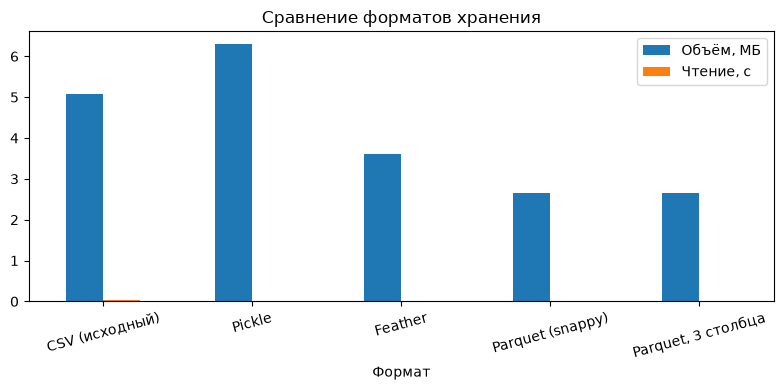

In [13]:
# Запускаем замер форматов
res_formats = benchmark_formats("../" + config.RAW_CITIES)
display(res_formats)

# Строим столбчатую диаграмму
res_formats.plot(x="Формат", y=["Объём, МБ", "Чтение, с"], kind="bar", figsize=(8, 4), title="Сравнение форматов хранения")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [14]:
df_before = pd.read_parquet(config.INTERIM_PARQUET)
mem_before = df_before.memory_usage(deep=True).sum() / (1024 ** 2)
size_before = os.path.getsize(config.INTERIM_PARQUET) / (1024 ** 2)

t0 = time.perf_counter()
_ = df_before.groupby("country")["population"].median()
group_before = time.perf_counter() - t0

# Применяем оптимизированную схему из config.py
df_after = df_before.astype(config.SCHEMA_CITIES)
df_after.to_parquet("../" + config.TYPED_PARQUET, compression="zstd")

mem_after = df_after.memory_usage(deep=True).sum() / (1024 ** 2)
size_after = os.path.getsize("../" + config.TYPED_PARQUET) / (1024 ** 2)

t0 = time.perf_counter()
_ = df_after.groupby("country", observed=True)["population"].median()
group_after = time.perf_counter() - t0

opt_table = pd.DataFrame([
    ["Объём файла на диске, МБ", round(size_before, 2), round(size_after, 2)],
    ["Объём в памяти, МБ", round(mem_before, 2), round(mem_after, 2)],
    ["Время группировки, с", round(group_before, 4), round(group_after, 4)],
    ["Число столбцов category", 0, 4]
], columns=["Показатель", "До оптимизации", "После"])
display(opt_table)

,Показатель,До оптимизации,После
0,"Объём файла на диске, МБ",2.6400,2.0100
1,"Объём в памяти, МБ",6.2900,3.8300
2,"Время группировки, с",0.0034,0.0014
3,Число столбцов category,0.0000,4.0000


In [15]:
path_pq = "../" + config.TYPED_PARQUET

# 1. Чтение
t0 = time.perf_counter()
df_pd = pd.read_parquet(path_pq)
t_pd_read = time.perf_counter() - t0

t0 = time.perf_counter()
df_pl = pl.read_parquet(path_pq)
t_pl_read = time.perf_counter() - t0

# 2. Фильтрация
t0 = time.perf_counter()
_ = df_pd[df_pd["population"] > 100000]
t_pd_filt = time.perf_counter() - t0

t0 = time.perf_counter()
_ = df_pl.filter(pl.col("population") > 100000)
t_pl_filt = time.perf_counter() - t0

# 3. Группировка
t0 = time.perf_counter()
_ = df_pd.groupby("country")["population"].median()
t_pd_grp = time.perf_counter() - t0

t0 = time.perf_counter()
_ = df_pl.group_by("country").agg(pl.col("population").median())
t_pl_grp = time.perf_counter() - t0

# 4. Цепочка в ленивом режиме Polars vs Pandas
t0 = time.perf_counter()
_ = (pd.read_parquet(path_pq)
     .query("population > 50000")
     .groupby("country")["population"]
     .median()
     .sort_values(ascending=False))
t_pd_chain = time.perf_counter() - t0

t0 = time.perf_counter()
_ = (pl.scan_parquet(path_pq)
     .filter(pl.col("population") > 50000)
     .group_by("country")
     .agg(pl.col("population").median())
     .sort("population", descending=True)
     .collect())
t_pl_chain = time.perf_counter() - t0

comp_df = pd.DataFrame([
    ["Чтение Parquet", t_pd_read, t_pl_read],
    ["Фильтрация", t_pd_filt, t_pl_filt],
    ["Группировка и медиана", t_pd_grp, t_pl_grp],
    ["Цепочка операций (lazy)", t_pd_chain, t_pl_chain]
], columns=["Операция", "pandas, с", "polars, с"])
comp_df["Ускорение (раз)"] = (comp_df["pandas, с"] / comp_df["polars, с"]).round(2)
display(comp_df)

,Операция,"pandas, с","polars, с",Ускорение (раз)
0,Чтение Parquet,0.009554,0.012983,0.74
1,Фильтрация,0.001501,0.000721,2.08
2,Группировка и медиана,0.001926,0.001417,1.36
3,Цепочка операций (lazy),0.011870,0.003528,3.36
